In [63]:
import pandas as pd
import numpy as np
import psycopg2
import sqlalchemy
import pandas.io.sql as sqlio 
from datetime import datetime
import xlrd
import matplotlib
import matplotlib.pyplot as plt 
from dateutil.relativedelta import relativedelta

In [64]:
Ganado = pd.read_excel(r'C:\Users\juan.valladares\Documents\Ganado\Base Predicción - Ganado.xlsx')

In [65]:
# Cargar y convertir la fecha
Ganado['Fecha Nacimiento'] = pd.to_datetime(Ganado['Fecha Nacimiento'])

hoy = pd.to_datetime("today")

# Cálculo de edad en una nueva columna
Ganado['Edad'] = Ganado['Fecha Nacimiento'].apply(
    lambda fecha: hoy.year - fecha.year - ((hoy.month, hoy.day) < (fecha.month, fecha.day))
)

# Función para calcular meses vividos
def calcular_meses(fecha):
    diff = relativedelta(hoy, fecha)
    return diff.years * 12 + diff.months

# Crear columna con meses vividos
Ganado['Meses'] = Ganado['Fecha Nacimiento'].apply(calcular_meses)


#Edad Conglomerada Año & Mes
def edad_texto(fecha):
    diff = relativedelta(hoy, fecha)
    return f"{diff.years} años {diff.months} meses"

Ganado['Edad Detallada'] = Ganado['Fecha Nacimiento'].apply(edad_texto)
Ganado 

,Número,Nombre,Sexo,Fecha Nacimiento,Estado Actual,Nombre Grupo Hacienda,Lote,Nombre Lote,Fecha Descarte,Fecha Ultimo Parto,...,Fecha Proximo Parto,Fecha Ultimo Servicio,Dias de Servida,N° Servicios,T. Ult. Serv.,Fecha Chequeo Ginecologico,Resultado Chequeo,Edad,Meses,Edad Detallada
0,14H-004,1065H,H,2014-12-16,Vaca Parida,FONTANA,L01,NaN,NaT,2024-10-30 00:00:00,...,- -,2025-03-01 00:00:00,46,2,2220,2025-02-17 00:00:00,ANESTRICA,10,124,10 años 4 meses
1,15H-004,1188H,H,2015-06-02,Vaca Seca,FONTANA,L01,NaN,NaT,2024-01-29 00:00:00,...,2025-08-31 00:00:00,2024-10-31 00:00:00,167,1,2220,2025-02-17 00:00:00,NaN,9,119,9 años 11 meses
2,15H-008,1308H,H,2015-10-24,Vaca Parida,FONTANA,L01,NaN,NaT,2024-08-15 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,114,9 años 6 meses
3,15H-009,1314H,H,2015-11-06,Vaca Seca,FONTANA,L01,NaN,NaT,2024-07-09 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,114,9 años 6 meses
4,15H-010,1328H,H,2015-11-22,Vaca Parida,FONTANA,L01,NaN,NaT,2024-09-26 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,113,9 años 5 meses
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1307,25H-004,NaN,H,2025-01-18,Cría Hembra,SANTA ANA,L09,NaN,NaT,- -,...,- -,- -,0,0,NaN,- -,NaN,0,3,0 años 3 meses
1308,25H-005AG,DOWNTOWN HG2,H,2025-03-17,Cría Hembra,CASHAPAMBA ALTA GENE,C5,CORRALES,NaT,- -,...,- -,- -,0,0,NaN,- -,NaN,0,1,0 años 1 meses
1309,25H-006AG,NOCHE BUENA HG1,H,2025-03-18,Cría Hembra,CASHAPAMBA ALTA GENE,C5,CORRALES,NaT,- -,...,- -,- -,0,0,NaN,- -,NaN,0,1,0 años 1 meses
1310,25H-007AG,CLEO HG1,H,2025-03-19,Cría Hembra,CASHAPAMBA ALTA GENE,C5,CORRALES,NaT,- -,...,- -,- -,0,0,NaN,- -,NaN,0,1,0 años 1 meses


In [66]:
Ganado['Fecha Descarte'] = pd.to_datetime(Ganado['Fecha Descarte'])

In [78]:
# Vacas vivas = sin fecha de descarte
vacas_vivas = Ganado[Ganado['Fecha Descarte'].isnull()]

In [81]:
# Filtrar hembras en edad reproductiva
vacas_reproductoras = vacas_vivas[
    (vacas_vivas['Sexo'].str.upper() == 'H') &
    (vacas_vivas['Meses'] >= 24)]
vacas_reproductoras

,Número,Nombre,Sexo,Fecha Nacimiento,Estado Actual,Nombre Grupo Hacienda,Lote,Nombre Lote,Fecha Descarte,Fecha Ultimo Parto,...,Fecha Proximo Parto,Fecha Ultimo Servicio,Dias de Servida,N° Servicios,T. Ult. Serv.,Fecha Chequeo Ginecologico,Resultado Chequeo,Edad,Meses,Edad Detallada
0,14H-004,1065H,H,2014-12-16,Vaca Parida,FONTANA,L01,NaN,NaT,2024-10-30 00:00:00,...,- -,2025-03-01 00:00:00,46,2,2220,2025-02-17 00:00:00,ANESTRICA,10,124,10 años 4 meses
1,15H-004,1188H,H,2015-06-02,Vaca Seca,FONTANA,L01,NaN,NaT,2024-01-29 00:00:00,...,2025-08-31 00:00:00,2024-10-31 00:00:00,167,1,2220,2025-02-17 00:00:00,NaN,9,119,9 años 11 meses
2,15H-008,1308H,H,2015-10-24,Vaca Parida,FONTANA,L01,NaN,NaT,2024-08-15 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,114,9 años 6 meses
3,15H-009,1314H,H,2015-11-06,Vaca Seca,FONTANA,L01,NaN,NaT,2024-07-09 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,114,9 años 6 meses
4,15H-010,1328H,H,2015-11-22,Vaca Parida,FONTANA,L01,NaN,NaT,2024-09-26 00:00:00,...,2025-09-30 00:00:00,2024-12-19 00:00:00,118,2,2220,2025-02-17 00:00:00,NaN,9,113,9 años 5 meses
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
823,23H-021,3272H,H,2023-04-24,Novilla Vientre,EL PONGO,L17,NaN,NaT,- -,...,- -,2025-03-27 00:00:00,20,2,DEMAND,2025-03-03 00:00:00,"VACIA NORMAL, PARC",2,24,2 años 0 meses
825,23H-023,3274H,H,2023-05-04,Novilla Vientre,EL PONGO,L17,NaN,NaT,- -,...,- -,2025-03-08 00:00:00,39,1,DEMAND,2025-03-03 00:00:00,"VACIA NORMAL, PARC",2,24,2 años 0 meses
826,23H-024,3275H,H,2023-05-04,Novilla Vientre,EL PONGO,L17,NaN,NaT,- -,...,- -,2025-03-27 00:00:00,20,2,DEMAND,2025-03-03 00:00:00,"VACIA NORMAL, PARC",2,24,2 años 0 meses
827,23H-025,3276H,H,2023-05-04,Novilla Vientre,EL PONGO,L17,NaN,NaT,- -,...,- -,2025-03-07 00:00:00,40,1,DEMAND,2025-03-03 00:00:00,"VACIA NORMAL, PARC",2,24,2 años 0 meses


In [82]:
#Conteo Poblacion Inicial 

poblacion_inicial = len(vacas_reproductoras)
limite = 4000
print("Población actual:", poblacion_inicial) 

Población actual: 790


In [ ]:
# Variables para dos Tipos de Escenarios #

anios = [] 
poblacion_opt = poblacion_inicial 
poblacion_real = poblacion_inicial
proyeccion_opt = []
proyeccion_real = []
anio_actual = pd.Timestamp.today().year
poblacion_total = poblacion_inicial
limite = 4000  

# Simulación año a año
while poblacion_opt < limite or poblacion_real < limite:
    anios.append(anio_actual)

    # ----- Modelo optimista -----
    preñadas_opt = int(poblacion_opt * 0.7)
    nuevas_opt = preñadas_opt  # Asumimos todas son hembras
    muertes_opt = int(poblacion_opt * 0.10)
    poblacion_opt = poblacion_opt + nuevas_opt - muertes_opt
    proyeccion_opt.append(poblacion_opt) 

    # ----- Modelo realista -----
    preñadas_real = int(poblacion_real * 0.7)
    nuevas_real = int(preñadas_real * 0.5)  # Solo el 50% son hembras
    muertes_real = int(poblacion_real * 0.10) 
    poblacion_real = poblacion_real + nuevas_real - muertes_real
    proyeccion_real.append(poblacion_real)   

    anio_actual += 1 

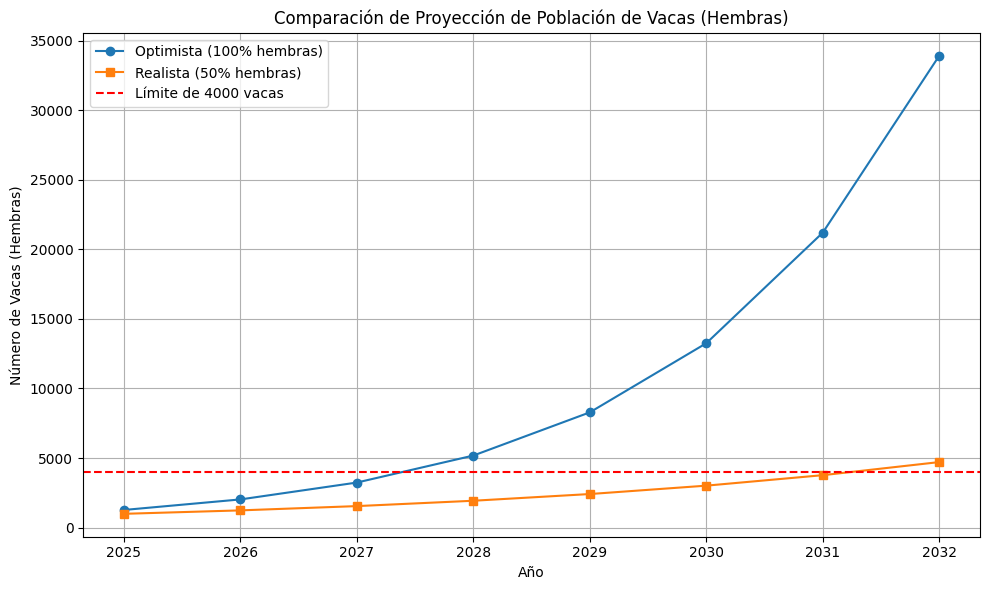

In [ ]:
# Gráfico #
plt.figure(figsize=(10,6))
plt.plot(anios, proyeccion_opt, marker='o', label='Optimista (100% hembras)')
plt.plot(anios, proyeccion_real, marker='s', label='Realista (50% hembras)')
plt.axhline(4000, color='red', linestyle='--', label='Límite de 4000 vacas')
plt.title("Comparación de Proyección de Población de Vacas (Hembras)")
plt.xlabel("Año")
plt.ylabel("Número de Vacas (Hembras)")
plt.legend() 
plt.grid(True)
plt.tight_layout()
plt.show()

In [85]:
# Variables para Escenario Real #

anios = [] 
poblacion_real = poblacion_inicial
proyeccion_real = []
anio_actual = pd.Timestamp.today().year
poblacion_total = poblacion_inicial
limite = 4000

# Simulación año a año
while poblacion_opt < limite or poblacion_real < limite:
    anios.append(anio_actual)


    # ----- Modelo realista -----
    preñadas_real = int(poblacion_real * 0.7)
    nuevas_real = int(preñadas_real * 0.5)  # Solo el 50% son hembras
    muertes_real = int(poblacion_real * 0.10) 
    poblacion_real = poblacion_real + nuevas_real - muertes_real
    proyeccion_real.append(poblacion_real)

    anio_actual += 1

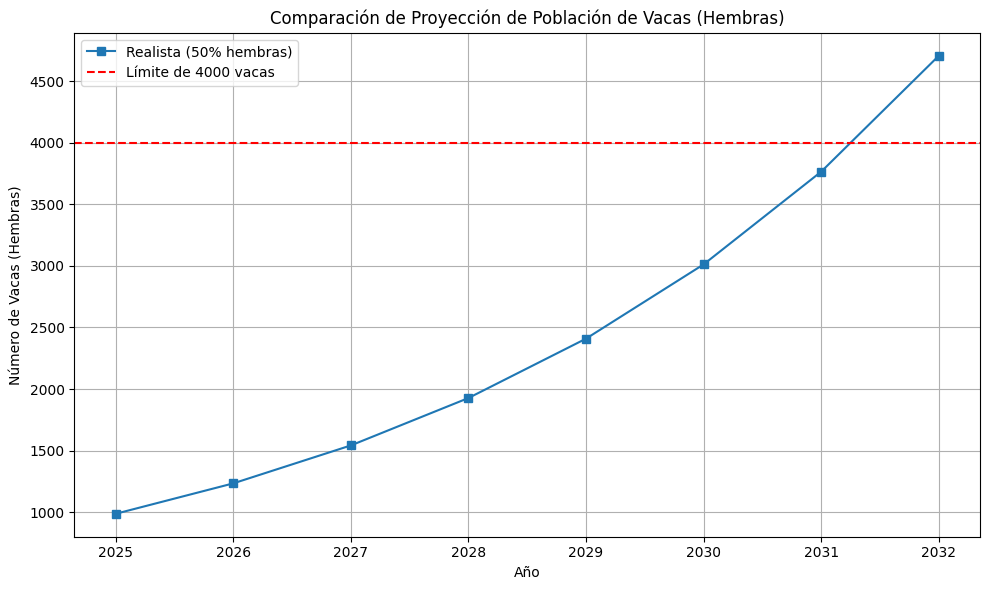

In [ ]:
# Gráfico #
plt.figure(figsize=(10,6))
plt.plot(anios, proyeccion_real, marker='s', label='Realista (50% hembras)')
plt.axhline(4000, color='red', linestyle='--', label='Límite de 4000 vacas')
plt.title("Comparación de Proyección de Población de Vacas (Hembras)")
plt.xlabel("Año")
plt.ylabel("Número de Vacas (Hembras)")
plt.legend()
plt.grid(True) 
plt.tight_layout() 
plt.show() 

In [87]:
# Fecha Actual #

hoy = pd.to_datetime('today')
anio_actual = pd.Timestamp.today().year
mes_actual = hoy.month  


In [88]:
# Parametros Mensuales #

tasa_preñez_mensual = 0.7/12
tasa_mortalidad_mensual = 0.10/12

In [89]:
# Variables para Escenario Mensual #

meses = [] 
poblacion_opt = poblacion_inicial 
poblacion_real = poblacion_inicial
opt_proy = []
real_proy = []
mes_actual = pd.Timestamp.today().month
poblacion_total = poblacion_inicial
limite = 4000

fecha = pd.to_datetime(f"{anio_actual}-{mes_actual}-01")

# Simulación Mes a Mes #

while poblacion_opt < limite or poblacion_real < limite:
    meses.append(fecha.strftime('%Y-%m'))

    # Optimista (100% crías Hembras)
    preñadas_opt = int(poblacion_opt * tasa_preñez_mensual)
    nuevas_opt = preñadas_opt
    muertes_opt = int(poblacion_opt * tasa_mortalidad_mensual)
    poblacion_opt = poblacion_opt + nuevas_opt - muertes_opt
    opt_proy.append(poblacion_opt)

    # Realista (50% crías Hembras)
    preñadas_real = int(poblacion_real * tasa_preñez_mensual)
    nuevas_real = int(preñadas_real * 0.5)
    muertes_real = int(poblacion_real * tasa_mortalidad_mensual)
    poblacion_real = poblacion_real + nuevas_real - muertes_real 
    real_proy.append(poblacion_real)

    # Siguientes mes 
    fecha += relativedelta(months= 1)

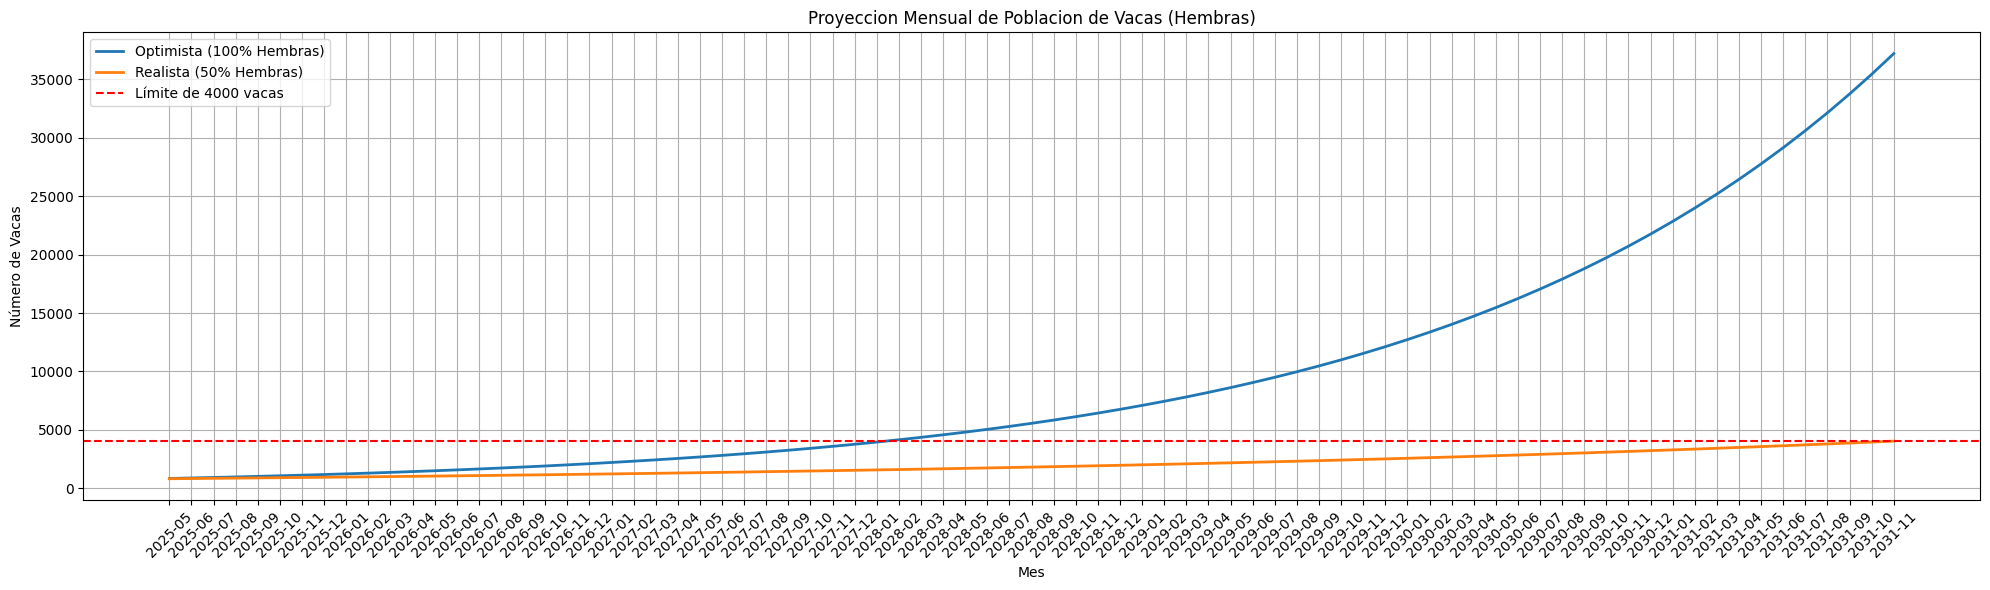

In [91]:
# Grafico #
plt.figure(figsize=(20, 6))
plt.plot(meses, opt_proy, label = 'Optimista (100% Hembras)', linewidth = 2)
plt.plot(meses, real_proy, label = 'Realista (50% Hembras)', linewidth = 2)
plt.axhline(4000, color = 'red', linestyle = '--', label = 'Límite de 4000 vacas')
plt.title("Proyeccion Mensual de Poblacion de Vacas (Hembras)")
plt.xlabel('Mes')
plt.ylabel('Número de Vacas')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()